# 2.24 · Observable versus weakly observable windows: calibration predictions and rollouts

**Frozen checkpoint:** `kaist_pooled_calibration_paired_002.16_correction_only/best.pt`. **Dataset:** held-out KAIST Urban38/Urban39 with one genuine IMU and two genuine LiDAR streams. **No training, no physical augmentation, no random sensor-frame perturbations.**

Goal: identify two **30 consecutive 5-second windows** from the scientific nominal Fisher/soft-projector cache: a low-mean-observability interval and a high-mean-observability interval. Use gyroscope yaw motion as an independent numerical check of the desired *straight-like* and *turn-like* behaviors. Start both intervals from **exactly the same sensor-specific initial SE(3) + clock perturbation**, and compare:

1. **Reset each window:** the original erroneous prior is restored before each inference. What does the network predict from the measurements *in this window*?
2. **Carry between windows:** the prediction updates the prior before the next inference. Does the estimate converge, drift, or change with observability?

Scientific observability is computed **once at nominal calibration** and serves only as a diagnostic label, never a model input. Every sensor remains an independent calibration variable. By default, the experiment perturbs and updates **one sensor per scenario** to match the checkpoint's training distribution. You can additionally select a simultaneous-fault scenario.

**Important limitations:** average observability does not prove every DOF is identifiable; it may not correlate with turning. Clock ground truth here is the KAIST nominal reference. The 6D output uses a left-multiplicative SE(3) tangent: the translation-like entries are **ρ components**, not necessarily direct changes in lever-arm coordinates.

## 1 · Imports and repository paths

In [1]:
from pathlib import Path
from dataclasses import replace
from itertools import combinations
import json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from scipy.spatial.transform import Rotation
from IPython.display import display

ROOT = Path.cwd()
for folder in (ROOT, *ROOT.parents):
    if (folder / 'src' / 'obscalib').is_dir():
        ROOT = folder
        break
else:
    raise FileNotFoundError('Open this notebook from the nn-obs-calib repository tree containing src/obscalib.')
if str(ROOT / 'src') not in sys.path: sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.config import WindowingConfig, PooledCalibrationModelConfig, TransformerConfig, MLPConfig, CalibrationPoolerConfig, PooledCalibrationHeadConfig
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.processing import GeometryProcessor
from obscalib.geometry.lie import so3_exp, se3_exp, se3_log
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint

print('Repository:', ROOT)
print('PyTorch:', torch.__version__)

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2 · Experiment settings

In [22]:
RUN_NAME = 'observability_window_calibration_dynamics'
CHECKPOINT = ROOT / 'runs' / 'kaist_pooled_calibration_paired_002.16_correction_only' / 'best.pt'
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
SEQUENCES = ('Urban38', 'Urban39')
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
DOF_NAMES = ('phi_x', 'phi_y', 'phi_z', 'rho_x', 'rho_y', 'rho_z', 'tau')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
SEGMENT_WINDOWS = 10                  # Thirty consecutive 5-second KAIST windows (~150 s).
LOW_OBSERVABILITY_PERCENTILE = 10.0  # Window-level threshold, not an impossible 30-window all-below requirement.
HIGH_OBSERVABILITY_PERCENTILE = 90.0
MOTION_TIE_BREAK_WEIGHT = 0.15        # Used only among near-extreme candidates, not instead of observability.
SAME_SEQUENCE_ALLOWED = True

# Identical numerical fault for both segments and every single-sensor scenario.
INITIAL_ROTATION_VECTOR_DEG = (18.0, -12.0, 8.0)
INITIAL_TRANSLATION_M = (0.01, -0.01, 0.005)
INITIAL_TIME_OFFSET_MS = 120.0
FAULT_SCENARIOS = CALIBRATION_KEYS    # Change to ('imu',) for a quick experiment, or append 'all_sensors'.

APPLY_ROTATION_UPDATES = True
APPLY_TRANSLATION_UPDATES = False     # 002.16 was not trained for arbitrary translation recovery; predictions are plotted regardless.
APPLY_TIME_UPDATES = True
ROTATION_UPDATE_GAIN = 1.0
TRANSLATION_UPDATE_GAIN = 1.0
TIME_UPDATE_GAIN = 1.0
MAX_ROTATION_STEP_DEG = 25.0           # Set None to use the raw predicted rotation.
MAX_TRANSLATION_STEP_M = 0.05
MAX_TIME_STEP_MS = 35.0

OBSERVABILITY_CACHE_DIR = ROOT / 'outputs' / 'observability_targets' / 'three_sensor'
LEGACY_OBSERVABILITY_CACHE_DIR = ROOT / 'outputs' / 'observability_targets'
OUTPUT_DIR = ROOT / 'runs' / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not CHECKPOINT.is_file(): raise FileNotFoundError(f'002.16 checkpoint missing: {CHECKPOINT}')
assert 0 < LOW_OBSERVABILITY_PERCENTILE < HIGH_OBSERVABILITY_PERCENTILE < 100
assert SEGMENT_WINDOWS >= 2 and all(name in (*CALIBRATION_KEYS, 'all_sensors') for name in FAULT_SCENARIOS)
print('Checkpoint:', CHECKPOINT)
print('Output directory:', OUTPUT_DIR)
print('Device:', DEVICE)
print('Initial rotation norm [deg]:', np.linalg.norm(INITIAL_ROTATION_VECTOR_DEG))

Checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt
Output directory: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/observability_window_calibration_dynamics
Device: cuda
Initial rotation norm [deg]: 23.065125189341593


## 3 · Held-out KAIST physical windows and compatible scientific observability cache

The cache metadata is checked against notebook 32’s schema. Stale/mismatched caches are **rejected**, not silently used. Generate missing caches with the existing notebook 31/32 scientific pipeline rather than replacing them with predicted observability.

In [23]:
T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_RIGHT = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.eye(4); T_I_B[:3, 3] = [-0.07, 0., 1.7]
rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_RIGHT, tau_lidar_right_s=0.0)
windowing = WindowingConfig(window_duration_s=5.0, window_stride_s=5.0, max_samples_per_sensor=700)
specs = build_kaist_sequence_specs(sequence_names=list(SEQUENCES), kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file(): raise FileNotFoundError(f'Missing actual right LiDAR for {spec.name}: {spec.lidar_right_pose_csv}')
dataset = KAISTCalibrationDataset(specs, rig, windowing, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS
print(dataset.summary())

# Match the scientific-cache metadata used in notebook 32 exactly.
def expected_cache_metadata(ds):
    return dict(cache_version=1, split_name='test', num_windows=len(ds), sequence_names=tuple(ds.sequence_name_for_window(i) for i in range(len(ds))), calibration_keys=CALIBRATION_KEYS, window_duration_s=5.0, window_stride_s=5.0, max_samples_per_sensor=700, dimensionless_calibration_scale=(np.deg2rad(5.), np.deg2rad(5.), np.deg2rad(5.), 0.05, 0.05, 0.05, 0.015), lambda_value_setting=0.25, reference_lidar_stream_key='lidar', numerical_relative_tolerance=1e-10, score_source='scientific_soft_projector_cached_or_computed')

expected_metadata = expected_cache_metadata(dataset)
cache_paths = (OBSERVABILITY_CACHE_DIR / 'test.pt', LEGACY_OBSERVABILITY_CACHE_DIR / 'test.pt')
cache_data = None
for candidate in cache_paths:
    if not candidate.is_file(): continue
    loaded = torch.load(candidate, map_location='cpu', weights_only=True)
    if not isinstance(loaded, dict) or 'values' not in loaded: continue
    differences = {k: (loaded.get('metadata', {}).get(k), v) for k, v in expected_metadata.items() if loaded.get('metadata', {}).get(k) != v}
    if differences:
        print(f'Rejecting incompatible cache {candidate}; differing keys:', list(differences))
        continue
    if tuple(loaded.get('calibration_keys', ())) != CALIBRATION_KEYS: continue
    scores = torch.as_tensor(loaded['values'], dtype=torch.float32)
    if scores.shape != (len(dataset), len(CALIBRATION_KEYS), 7) or not torch.isfinite(scores).all() or bool(((scores < 0) | (scores > 1)).any()):
        raise ValueError(f'Invalid scientific observability scores in {candidate}: {tuple(scores.shape)}')
    cache_data = loaded
    cache_path = candidate
    scientific_scores = scores.numpy()
    break
if cache_data is None: raise FileNotFoundError(f'No compatible 3-sensor test cache found at {cache_paths}. Regenerate it using notebook 31/32 without altering estimator settings.')
print('Loaded verified scientific cache:', cache_path, '| shape:', scientific_scores.shape)

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR=17005, right LiDAR=17004
  Urban39: windows=350, duration=1856.3s, IMU=186682, LiDAR=17195, right LiDAR=17197
Loaded verified scientific cache: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/three_sensor/test.pt | shape: (699, 3, 7)


## 4 · Numerically identify low- and high-observability contiguous intervals

A strict requirement that every one of 30 successive windows lies in the bottom 20% (or top 10%) is usually unrealistic. Instead, calculate the **mean of all 21 DOF scores in each 5-second window**, then rank *contiguous 30-window rolling means*. The requested 20th and 90th percentiles are reported as reference thresholds, along with each selected segment's fraction of individual windows below/above them.

For an independent physical proxy, use the **nominally calibrated IMU angular velocity projected onto the KAIST body Z axis**. High |ω_z| is *turn-like*; low |ω_z| is *straight-like*, but stationary and other motions can look similar. The selector first seeks joint rolling-mean observability extremes (bottom 20% versus top 10% of all candidate 30-window intervals) with low versus high yaw-motion quantiles; if this is infeasible, it falls back with an explicit warning. Within eligible candidates it prioritizes observability, using motion as a tie-breaker. The diagnostic prints the actual yaw numbers, so the labels are never based solely on the cache.

In [24]:
window_mean_scores = scientific_scores.mean(axis=(1, 2))
window_rotation_scores = scientific_scores[:, :, :3].mean(axis=(1, 2))
window_time_scores = scientific_scores[:, :, 6].mean(axis=1)
low_threshold = float(np.percentile(window_mean_scores, LOW_OBSERVABILITY_PERCENTILE))
high_threshold = float(np.percentile(window_mean_scores, HIGH_OBSERVABILITY_PERCENTILE))

# A physically independent turn proxy: mean absolute body-Z gyro rate and integrated signed yaw.
def yaw_motion_features(index):
    sample = dataset[int(index)]
    gyro = np.asarray(sample.streams['gyro'].values.detach().cpu(), dtype=float)
    ts = np.asarray(sample.streams['gyro'].timestamps.detach().cpu(), dtype=float)
    gyro = gyro.reshape(-1, 3); ts = ts.reshape(-1)
    R_BI = np.asarray(sample.current_calibration['imu'].transform.detach().cpu(), dtype=float).reshape(-1, 4, 4)[0, :3, :3]
    wz = (R_BI @ gyro.T)[2]
    return float(np.mean(np.abs(wz))), float(np.rad2deg(np.trapz(wz, ts)))

motion_abs = np.zeros(len(dataset), dtype=float)
motion_signed = np.zeros(len(dataset), dtype=float)
for i in tqdm(range(len(dataset)), desc='Independent yaw-motion proxy'):
    motion_abs[i], motion_signed[i] = yaw_motion_features(i)

candidates = []
for sequence in SEQUENCES:
    indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=int)
    for local_start in range(len(indices) - SEGMENT_WINDOWS + 1):
        block = indices[local_start:local_start + SEGMENT_WINDOWS]
        if not np.all(np.diff(block) == 1): continue
        window_scores = window_mean_scores[block]
        candidates.append(dict(sequence=sequence, local_start=local_start, first=int(block[0]), last=int(block[-1]), indices=block, mean_observability=float(window_scores.mean()), median_observability=float(np.median(window_scores)), fraction_below_p20=float(np.mean(window_scores <= low_threshold)), fraction_above_p90=float(np.mean(window_scores >= high_threshold)), mean_abs_yaw_degps=float(np.rad2deg(motion_abs[block].mean())), mean_abs_net_yaw_deg=float(np.mean(np.abs(motion_signed[block]))), net_yaw_deg=float(np.sum(motion_signed[block]))))
if len(candidates) < 2: raise RuntimeError(f'Not enough uninterrupted {SEGMENT_WINDOWS}-window intervals in {SEQUENCES}')

candidate_df = pd.DataFrame([{k: v for k, v in c.items() if k != 'indices'} for c in candidates])
# Prefer joint observability-and-motion contrasts. Require the desired percentile extremes whenever feasible.
ranked_low = sorted(candidates, key=lambda c: c['mean_observability'])
ranked_high = sorted(candidates, key=lambda c: c['mean_observability'], reverse=True)
rolling_low_cut = float(candidate_df.mean_observability.quantile(.20))
rolling_high_cut = float(candidate_df.mean_observability.quantile(.90))
yaw_low_cut = float(candidate_df.mean_abs_yaw_degps.quantile(.30))
yaw_high_cut = float(candidate_df.mean_abs_yaw_degps.quantile(.70))
low_candidates = [c for c in candidates if c['mean_observability'] <= rolling_low_cut and c['mean_abs_yaw_degps'] <= yaw_low_cut]
if not low_candidates:
    warnings.warn('No 30-window interval simultaneously satisfies bottom-20% observability and bottom-30% yaw. Selecting the lowest-observability interval, and checking its actual yaw separately.')
    low_candidates = ranked_low[:max(1, int(np.ceil(.10 * len(candidates))))]
low_segment = min(low_candidates, key=lambda c: c['mean_observability'] + MOTION_TIE_BREAK_WEIGHT * (c['mean_abs_yaw_degps'] / max(candidate_df.mean_abs_yaw_degps.max(), 1e-9)) * max(np.std(candidate_df.mean_observability), 1e-9))

def is_nonoverlapping(a, b):
    if a['sequence'] != b['sequence']: return True
    return a['last'] < b['first'] or b['last'] < a['first']

def eligible_high(c):
    return is_nonoverlapping(low_segment, c) and (SAME_SEQUENCE_ALLOWED or c['sequence'] != low_segment['sequence'])

high_candidates = [c for c in candidates if eligible_high(c) and c['mean_observability'] >= rolling_high_cut and c['mean_abs_yaw_degps'] >= yaw_high_cut]
if not high_candidates:
    warnings.warn('No nonoverlapping 30-window interval satisfies top-10% observability AND top-30% yaw. Selecting from high observability intervals and reporting its measured turn rate.')
    high_candidates = [c for c in ranked_high[:max(1, int(np.ceil(.10 * len(candidates))))] if eligible_high(c)]
if not high_candidates: high_candidates = [c for c in ranked_high if eligible_high(c)]
if not high_candidates: raise RuntimeError('Could not find two nonoverlapping segments. Shorten SEGMENT_WINDOWS or permit both sequences.')
high_segment = max(high_candidates, key=lambda c: c['mean_observability'] + MOTION_TIE_BREAK_WEIGHT * (c['mean_abs_yaw_degps'] / max(candidate_df.mean_abs_yaw_degps.max(), 1e-9)) * max(np.std(candidate_df.mean_observability), 1e-9))
segments = {'low_observability': low_segment, 'high_observability': high_segment}

print(f'Window-level scientific mean score thresholds: P{LOW_OBSERVABILITY_PERCENTILE:g}={low_threshold:.4f}, P{HIGH_OBSERVABILITY_PERCENTILE:g}={high_threshold:.4f}')
summary = pd.DataFrame([{k: v for k, v in seg.items() if k != 'indices'} | {'type': label} for label, seg in segments.items()]).set_index('type')
display(summary.round(4))
summary.to_csv(OUTPUT_DIR / 'selected_segment_summary.csv')
candidate_df.to_csv(OUTPUT_DIR / 'all_contiguous_segment_candidates.csv', index=False)

low_motion, high_motion = low_segment['mean_abs_yaw_degps'], high_segment['mean_abs_yaw_degps']
print(f'Physical turn proxy: low-observability yaw |ωz|={low_motion:.3f}°/s; high-observability yaw |ωz|={high_motion:.3f}°/s')
if high_motion <= low_motion: warnings.warn('High-observability segment is NOT more turn-like by the yaw proxy. Do not label it a turn without examining the plot. Try a different sequence or shorten the interval.')
if low_segment['fraction_below_p20'] < 0.5 or high_segment['fraction_above_p90'] < 0.10: warnings.warn('The selected contiguous segments do not contain many individually extreme percentile windows. The ranking is by the 30-window mean; see fractions in the summary table.')

Independent yaw-motion proxy:   0%|          | 0/699 [00:00<?, ?it/s]

Window-level scientific mean score thresholds: P10=0.0442, P90=0.3408


,sequence,local_start,first,last,mean_observability,median_observability,fraction_below_p20,fraction_above_p90,mean_abs_yaw_degps,mean_abs_net_yaw_deg,net_yaw_deg
type,,,,,,,,,,,
low_observability,Urban39,109,458,467,0.0357,0.0338,0.8,0.0,0.1267,0.5950,-5.9498
high_observability,Urban39,329,678,687,0.3480,0.3585,0.0,0.6,3.8452,17.1814,159.2168


Physical turn proxy: low-observability yaw |ωz|=0.127°/s; high-observability yaw |ωz|=3.845°/s


## 5 · Visual inspection: cached observability, DOF heatmaps and turning motion

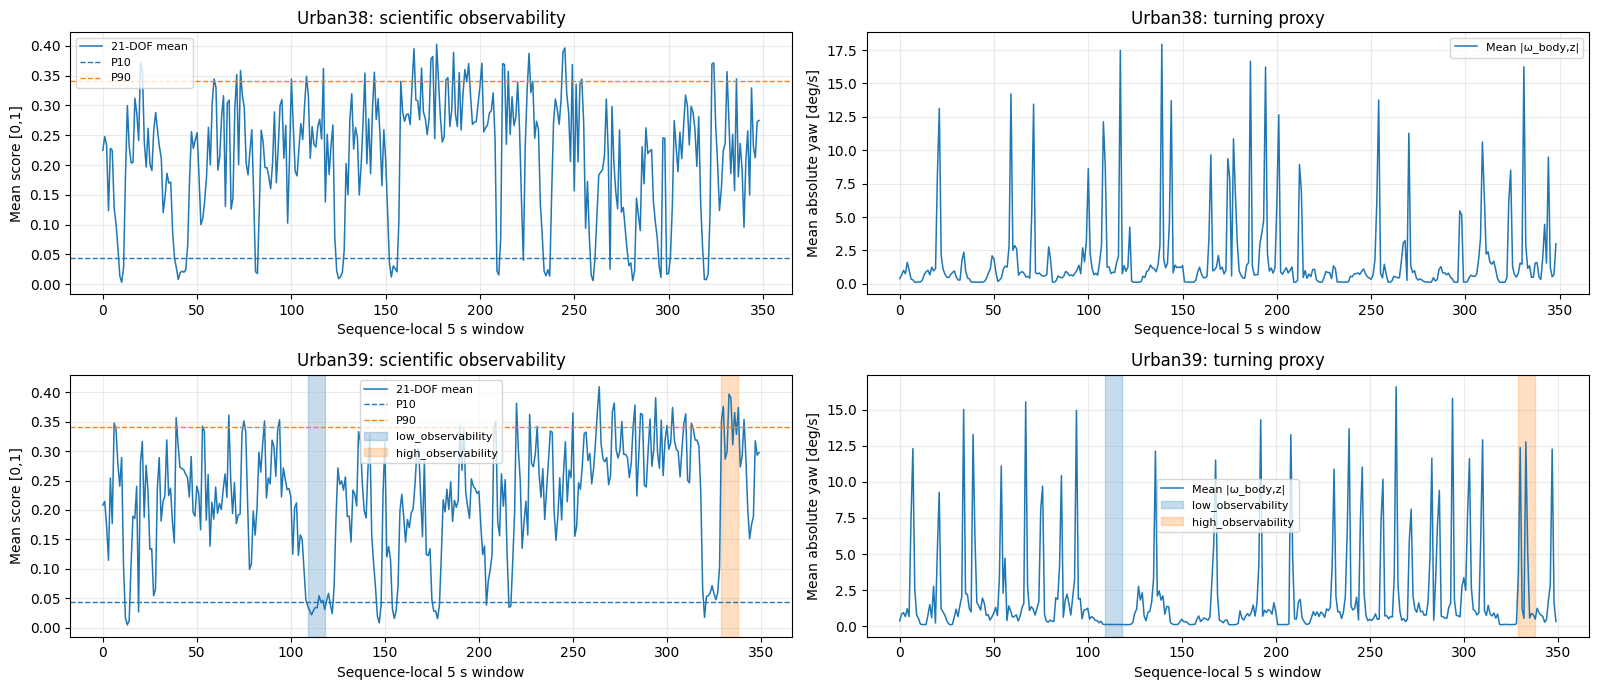

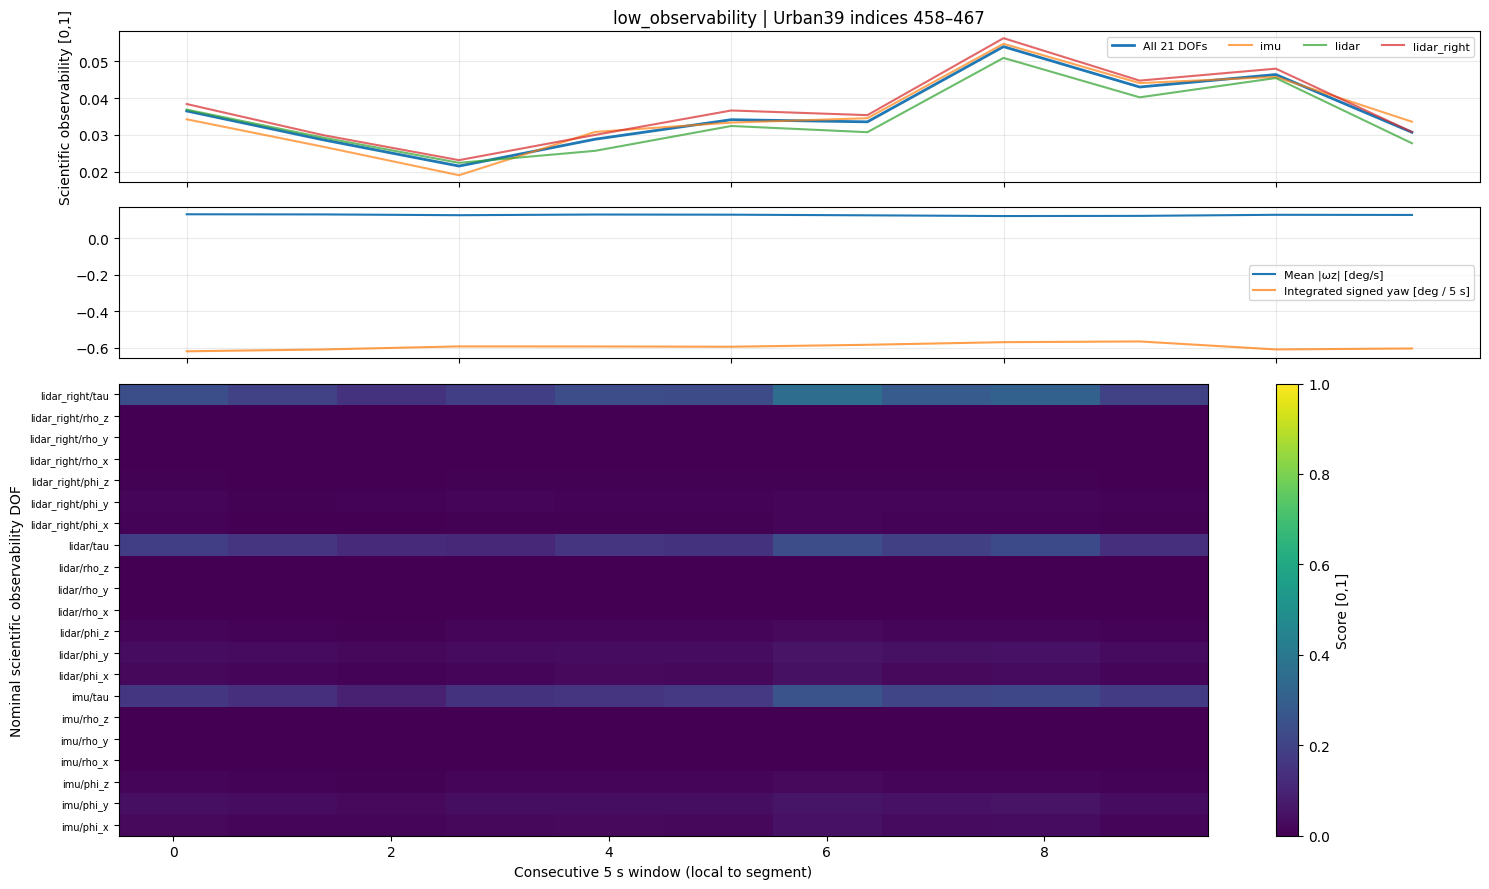

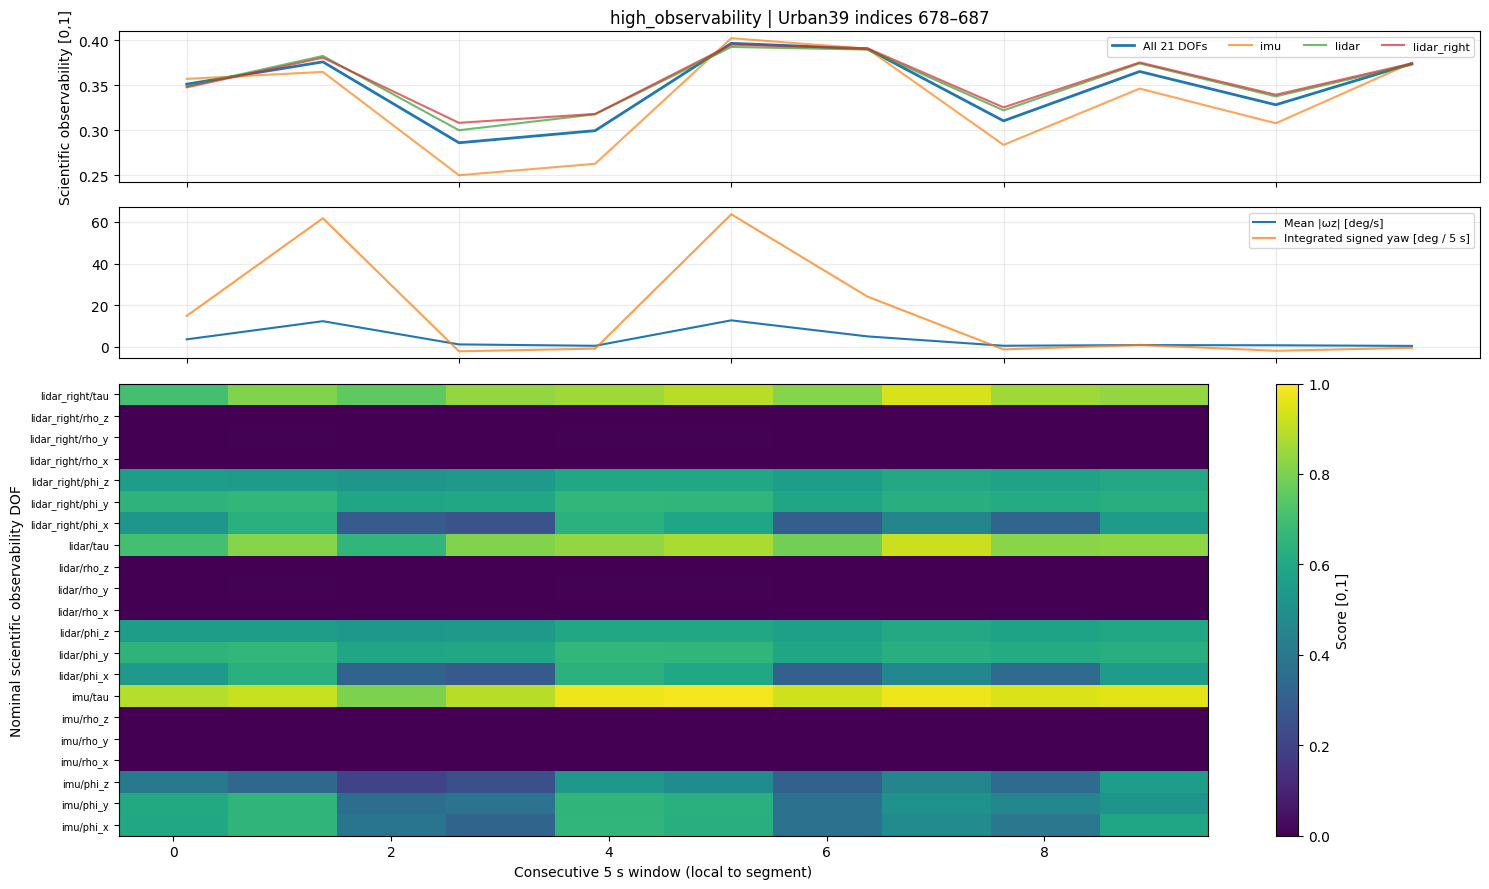

In [25]:
fig, axes = plt.subplots(len(SEQUENCES), 2, figsize=(16, 7), squeeze=False)
for row, seq in enumerate(SEQUENCES):
    idx = np.asarray(dataset.window_indices_for_sequence(seq), dtype=int)
    axes[row, 0].plot(np.arange(len(idx)), window_mean_scores[idx], lw=1.1, label='21-DOF mean')
    axes[row, 0].axhline(low_threshold, color='tab:blue', ls='--', lw=1, label=f'P{LOW_OBSERVABILITY_PERCENTILE:g}')
    axes[row, 0].axhline(high_threshold, color='tab:orange', ls='--', lw=1, label=f'P{HIGH_OBSERVABILITY_PERCENTILE:g}')
    axes[row, 1].plot(np.arange(len(idx)), np.rad2deg(motion_abs[idx]), lw=1.1, label='Mean |ω_body,z|')
    for label, seg in segments.items():
        if seg['sequence'] != seq: continue
        for ax in axes[row]: ax.axvspan(seg['local_start'], seg['local_start'] + SEGMENT_WINDOWS - 1, alpha=.25, color='tab:blue' if label.startswith('low') else 'tab:orange', label=label)
    axes[row, 0].set(title=f'{seq}: scientific observability', xlabel='Sequence-local 5 s window', ylabel='Mean score [0,1]')
    axes[row, 1].set(title=f'{seq}: turning proxy', xlabel='Sequence-local 5 s window', ylabel='Mean absolute yaw [deg/s]')
    for ax in axes[row]: ax.grid(alpha=.25); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'segment_selection.png', dpi=160); plt.show(); plt.close(fig)

for label, seg in segments.items():
    ix = seg['indices']; data = scientific_scores[ix].transpose(1, 2, 0).reshape(21, len(ix))
    fig, axs = plt.subplots(3, 1, figsize=(15, 9), sharex=True, gridspec_kw={'height_ratios': [1, 1, 3]})
    axs[0].plot(window_mean_scores[ix], label='All 21 DOFs', lw=2)
    for j, key in enumerate(CALIBRATION_KEYS): axs[0].plot(scientific_scores[ix, j].mean(axis=1), label=key, alpha=.7)
    axs[0].set(ylabel='Scientific observability [0,1]', title=f'{label} | {seg["sequence"]} indices {seg["first"]}–{seg["last"]}')
    axs[0].legend(ncol=4, fontsize=8); axs[0].grid(alpha=.25)
    axs[1].plot(np.rad2deg(motion_abs[ix]), label='Mean |ωz| [deg/s]')
    axs[1].plot(motion_signed[ix], label='Integrated signed yaw [deg / 5 s]', alpha=.75)
    axs[1].legend(fontsize=8); axs[1].grid(alpha=.25)
    image = axs[2].imshow(data, aspect='auto', origin='lower', vmin=0, vmax=1, cmap='viridis')
    axs[2].set_yticks(np.arange(21), [f'{key}/{dof}' for key in CALIBRATION_KEYS for dof in DOF_NAMES], fontsize=7)
    axs[2].set(xlabel='Consecutive 5 s window (local to segment)', ylabel='Nominal scientific observability DOF')
    fig.colorbar(image, ax=axs[2], label='Score [0,1]')
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / f'{label}_observability_and_yaw.png', dpi=160); plt.show(); plt.close(fig)

## 6 · Load checkpoint 002.16 and verify the original tokenizer/model

In [26]:
config = PooledCalibrationModelConfig(transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'), mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0), pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0), head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0))
model = PooledCalibrationModel(config).to(device=DEVICE, dtype=MODEL_DTYPE)
checkpoint_info = load_training_checkpoint(CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
model.eval().requires_grad_(False)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)

def copy_states(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}

@torch.inference_mode()
def predict_from_window(physical_window, states):
    # GT calibration is never passed as a target or input: only measured streams and the current candidate are passed.
    candidate_window = replace(physical_window, current_calibration=states)
    canonical = geometry_processor(candidate_window.streams, candidate_window.metadata, candidate_window.current_calibration)
    tokens = tokenizer(canonical, observability=None)
    assert tuple(tokens.calibration_keys) == CALIBRATION_KEYS and tokens.x.shape[-1] == 8
    context = {key: calibration_state_to_context(states[key]) for key in CALIBRATION_KEYS}
    return model(tokens, context)

smoke = window_batch_to(collate_windows([dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
with torch.inference_mode():
    smoke_output = predict_from_window(smoke, smoke.current_calibration)
    assert all(torch.isfinite(smoke_output.predictions[key].delta_xi).all() and torch.isfinite(smoke_output.predictions[key].delta_tau).all() for key in CALIBRATION_KEYS)
print('Frozen 002.16 checkpoint loaded and measurement-only inference smoke test passed. Epoch:', checkpoint_info.get('epoch'))

Frozen 002.16 checkpoint loaded and measurement-only inference smoke test passed. Epoch: 97


## 7 · Identical initial fault and controlled update rules

Every scenario starts from the **same numerical** \(\delta\phi\), \(\delta t\), and \(\delta	au\) in both segments. Default: only one selected sensor is initially faulty and updated. The model still emits corrections for *all three heads*, and all are recorded. Set `FAULT_SCENARIOS = (*CALIBRATION_KEYS, 'all_sensors')` to additionally study coupled faults (out of the checkpoint's original single-sensor training distribution).

Plots label `delta_xi[3:]` as **SE(3) tangent ρ**. Physical lever-arm translation error is measured separately. When `APPLY_TRANSLATION_UPDATES=False`, the model's predicted ρ is still shown, but it is **not applied** to the rig.

In [27]:
def initialize_candidate(truth, scenario):
    states = copy_states(truth)
    keys_to_fault = CALIBRATION_KEYS if scenario == 'all_sensors' else (scenario,)
    for key in keys_to_fault:
        state = states[key]; T = state.transform.clone()
        vector = torch.tensor(INITIAL_ROTATION_VECTOR_DEG, device=T.device, dtype=T.dtype).reshape(1, 3).expand(T.shape[0], -1)
        T[:, :3, :3] = so3_exp(torch.deg2rad(vector)) @ T[:, :3, :3]
        T[:, :3, 3] = T[:, :3, 3] + torch.tensor(INITIAL_TRANSLATION_M, device=T.device, dtype=T.dtype).reshape(1, 3)
        tau = state.time_offset + INITIAL_TIME_OFFSET_MS / 1000.0
        states[key] = CalibrationState(transform=T, time_offset=tau)
    return states

def bounded_vector(vector, maximum):
    if maximum is None: return vector
    length = torch.linalg.vector_norm(vector, dim=-1, keepdim=True).clamp_min(1e-12)
    return vector * (float(maximum) / length).clamp(max=1.0)

def update_candidate(states, output, scenario):
    updated = copy_states(states)
    selected = CALIBRATION_KEYS if scenario == 'all_sensors' else (scenario,)
    for key in selected:
        s = states[key]; pred = output.predictions[key]
        dr = bounded_vector(ROTATION_UPDATE_GAIN * pred.delta_xi[:, :3], None if MAX_ROTATION_STEP_DEG is None else np.deg2rad(MAX_ROTATION_STEP_DEG)) if APPLY_ROTATION_UPDATES else torch.zeros_like(pred.delta_xi[:, :3])
        dt = bounded_vector(TRANSLATION_UPDATE_GAIN * pred.delta_xi[:, 3:], MAX_TRANSLATION_STEP_M) if APPLY_TRANSLATION_UPDATES else torch.zeros_like(pred.delta_xi[:, 3:])
        T = s.transform.clone()
        if APPLY_TRANSLATION_UPDATES: T = se3_exp(torch.cat((dr, dt), dim=-1)) @ T
        elif APPLY_ROTATION_UPDATES: T[:, :3, :3] = so3_exp(dr) @ T[:, :3, :3]
        dtau = (TIME_UPDATE_GAIN * pred.delta_tau).clamp(min=-MAX_TIME_STEP_MS / 1000., max=MAX_TIME_STEP_MS / 1000.) if APPLY_TIME_UPDATES else torch.zeros_like(s.time_offset)
        updated[key] = CalibrationState(transform=T, time_offset=s.time_offset + dtau)
    return updated

def calibration_error_values(current, truth):
    # Exact left-multiplicative SE(3) correction from current candidate to nominal GT.
    target_xi = se3_log(truth.transform @ torch.linalg.inv(current.transform))[0].detach().cpu().numpy().astype(float)
    target_tau = float((truth.time_offset - current.time_offset).detach().cpu().reshape(-1)[0])
    delta_R = truth.transform[0, :3, :3] @ current.transform[0, :3, :3].transpose(-1, -2)
    rotation_error = float(np.rad2deg(Rotation.from_matrix(delta_R.detach().cpu().numpy()).magnitude()))
    translation_error = float(torch.linalg.vector_norm(truth.transform[0, :3, 3] - current.transform[0, :3, 3]).item())
    return target_xi, target_tau, rotation_error, translation_error

# Verify the original fault is deterministic across both segments, including translation and tau.
for scenario in FAULT_SCENARIOS:
    verification = []
    for segment_name, seg in segments.items():
        w = window_batch_to(collate_windows([dataset[seg['indices'][0]]]), DEVICE, dtype=MODEL_DTYPE)
        candidate = initialize_candidate(w.current_calibration, scenario)
        verification.append({key: calibration_error_values(candidate[key], w.current_calibration[key])[:2] for key in CALIBRATION_KEYS})
    for key in CALIBRATION_KEYS:
        np.testing.assert_allclose(verification[0][key][0], verification[1][key][0], rtol=0, atol=1e-5)
        assert abs(verification[0][key][1] - verification[1][key][1]) < 1e-5
print('Identical spatial + time-offset initialization across the two selected segments: PASS')

Identical spatial + time-offset initialization across the two selected segments: PASS


## 8 · Evaluate two protocols (independent one-step vs carried state) on both segments

Each plotted prediction comes from **one actual 5-second window**. For each step, save all seven predicted and ideal correction components for all three heads, nominal observability scores, and resulting physical calibration error. No model parameters are updated.

In [28]:
# Reuse the same physical windows across fault scenarios and inference protocols.
physical_segments = {label: [window_batch_to(collate_windows([dataset[int(i)]]), DEVICE, dtype=MODEL_DTYPE) for i in seg['indices']] for label, seg in segments.items()}

rows = []
with torch.inference_mode():
    for scenario in FAULT_SCENARIOS:
        for label, windows in physical_segments.items():
            indices = segments[label]['indices']
            reference = windows[0].current_calibration
            initial = initialize_candidate(reference, scenario)
            for protocol in ('one_step_reset', 'sequential_rollout'):
                state = copy_states(initial)
                for step, (window, global_index) in enumerate(tqdm(zip(windows, indices), total=len(windows), desc=f'{scenario} / {label} / {protocol}'), start=1):
                    candidate = copy_states(initial) if protocol == 'one_step_reset' else state
                    output = predict_from_window(window, candidate)
                    next_state = update_candidate(candidate, output, scenario)
                    for sensor_id, key in enumerate(CALIBRATION_KEYS):
                        pred = output.predictions[key]
                        pred_xi = pred.delta_xi[0].detach().cpu().numpy().astype(float)
                        pred_tau = float(pred.delta_tau.detach().cpu().reshape(-1)[0])
                        ideal_xi, ideal_tau, before_rot, before_trans = calibration_error_values(candidate[key], reference[key])
                        _, _, after_rot, after_trans = calibration_error_values(next_state[key], reference[key])
                        row = dict(segment=label, sequence=segments[label]['sequence'], scenario=scenario, protocol=protocol, sensor=key, active_sensor=(scenario == 'all_sensors' or key == scenario), step=step, dataset_index=int(global_index), mean_observability=float(scientific_scores[global_index].mean()), sensor_observability=float(scientific_scores[global_index, sensor_id].mean()), rotation_observability=float(scientific_scores[global_index, sensor_id, :3].mean()), translation_observability=float(scientific_scores[global_index, sensor_id, 3:6].mean()), tau_observability=float(scientific_scores[global_index, sensor_id, 6]), yaw_abs_degps=float(np.rad2deg(motion_abs[global_index])), true_rotation_error_before_deg=before_rot, true_rotation_error_after_deg=after_rot, true_translation_error_before_m=before_trans, true_translation_error_after_m=after_trans, true_tau_error_before_ms=float(1000 * abs(ideal_tau)), pred_tau_ms=pred_tau * 1000, ideal_tau_ms=ideal_tau * 1000)
                        for j, dof in enumerate(DOF_NAMES[:6]):
                            scale = 180.0 / np.pi if j < 3 else 100.0
                            row[f'pred_{dof}'] = float(pred_xi[j] * scale)
                            row[f'ideal_{dof}'] = float(ideal_xi[j] * scale)
                            row[f'obs_{dof}'] = float(scientific_scores[global_index, sensor_id, j])
                        row['obs_tau'] = float(scientific_scores[global_index, sensor_id, 6])
                        row['rotation_gain_deg'] = before_rot - after_rot
                        rows.append(row)
                    if protocol == 'sequential_rollout': state = next_state

results = pd.DataFrame(rows)
results.to_csv(OUTPUT_DIR / 'all_window_predictions_observability.csv', index=False)
print('Saved', len(results), 'per-sensor prediction rows; scenarios=', tuple(FAULT_SCENARIOS))
print('Translation updates:', APPLY_TRANSLATION_UPDATES, '; time updates:', APPLY_TIME_UPDATES)
display(results.head(6).round(3))

imu / low_observability / one_step_reset:   0%|          | 0/10 [00:00<?, ?it/s]

imu / low_observability / sequential_rollout:   0%|          | 0/10 [00:00<?, ?it/s]

imu / high_observability / one_step_reset:   0%|          | 0/10 [00:00<?, ?it/s]

imu / high_observability / sequential_rollout:   0%|          | 0/10 [00:00<?, ?it/s]

lidar / low_observability / one_step_reset:   0%|          | 0/10 [00:00<?, ?it/s]

...

lidar_right / low_observability / sequential_rollout:   0%|          | 0/10 [00:00<?, ?it/s]

lidar_right / high_observability / one_step_reset:   0%|          | 0/10 [00:00<?, ?it/s]

lidar_right / high_observability / sequential_rollout:   0%|          | 0/10 [00:00<?, ?it/s]

Saved 360 per-sensor prediction rows; scenarios= ('imu', 'lidar', 'lidar_right')
Translation updates: False ; time updates: True


,segment,sequence,scenario,protocol,sensor,active_sensor,step,dataset_index,mean_observability,sensor_observability,...,ideal_rho_x,obs_rho_x,pred_rho_y,ideal_rho_y,obs_rho_y,pred_rho_z,ideal_rho_z,obs_rho_z,obs_tau,rotation_gain_deg
0,low_observability,Urban39,imu,one_step_reset,imu,True,1,458,0.036,0.034,...,34.62,0.0,-0.034,55.373,0.0,-0.018,0.914,0.0,0.158,19.899
1,low_observability,Urban39,imu,one_step_reset,lidar,False,1,458,0.036,0.037,...,-0.00,0.0,0.009,-0.000,0.0,0.016,-0.000,0.0,0.186,0.000
2,low_observability,Urban39,imu,one_step_reset,lidar_right,False,1,458,0.036,0.038,...,-0.00,0.0,0.005,0.000,0.0,0.024,0.000,0.0,0.241,0.000
3,low_observability,Urban39,imu,one_step_reset,imu,True,2,459,0.029,0.027,...,34.62,0.0,-0.033,55.373,0.0,-0.017,0.914,0.0,0.133,19.854
4,low_observability,Urban39,imu,one_step_reset,lidar,False,2,459,0.029,0.029,...,-0.00,0.0,0.004,-0.000,0.0,0.019,-0.000,0.0,0.155,0.000
5,low_observability,Urban39,imu,one_step_reset,lidar_right,False,2,459,0.029,0.030,...,-0.00,0.0,0.007,0.000,0.0,0.028,0.000,0.0,0.196,0.000


## 9 · Compare correction quality and drift, stratified by observability

One-step gain indicates whether the network correctly uses that window to improve the **same initial fault**. Sequential final error shows whether accumulation helps or hurts. The scientific scores refer to the nominal physical windows, not the perturbed candidate Fisher matrix.

,scenario,protocol,sensor,segment,mean_observability,mean_rotation_observability,mean_tau_observability,mean_rotation_gain_deg,fraction_rotation_improving,initial_rotation_error_deg,final_rotation_error_deg,mean_pred_rotation_deg,final_tau_error_before_ms
0,imu,one_step_reset,imu,low_observability,0.036,0.026,0.171,20.777,1.0,23.065,2.383,22.310,120.000
1,imu,sequential_rollout,imu,low_observability,0.036,0.026,0.171,2.164,0.4,23.065,1.428,2.533,14.336
2,imu,one_step_reset,imu,high_observability,0.348,0.471,0.926,18.858,1.0,23.065,11.466,23.434,120.000
3,imu,sequential_rollout,imu,high_observability,0.348,0.471,0.926,2.137,0.4,23.065,1.691,3.619,7.739
4,lidar,one_step_reset,lidar,low_observability,0.036,0.024,0.167,16.434,1.0,23.065,7.039,24.760,120.000
5,lidar,sequential_rollout,lidar,low_observability,0.036,0.024,0.167,1.769,0.6,23.065,5.377,3.564,17.114
6,lidar,one_step_reset,lidar,high_observability,0.348,0.556,0.805,14.038,0.9,23.065,29.686,20.845,120.000
7,lidar,sequential_rollout,lidar,high_observability,0.348,0.556,0.805,1.632,0.4,23.065,6.749,3.648,6.731
8,lidar_right,one_step_reset,lidar_right,low_observability,0.036,0.008,0.238,9.769,1.0,23.065,9.873,20.682,120.000
9,lidar_right,sequential_rollout,lidar_right,low_observability,0.036,0.008,0.238,-0.382,0.4,23.065,26.887,8.254,8.387


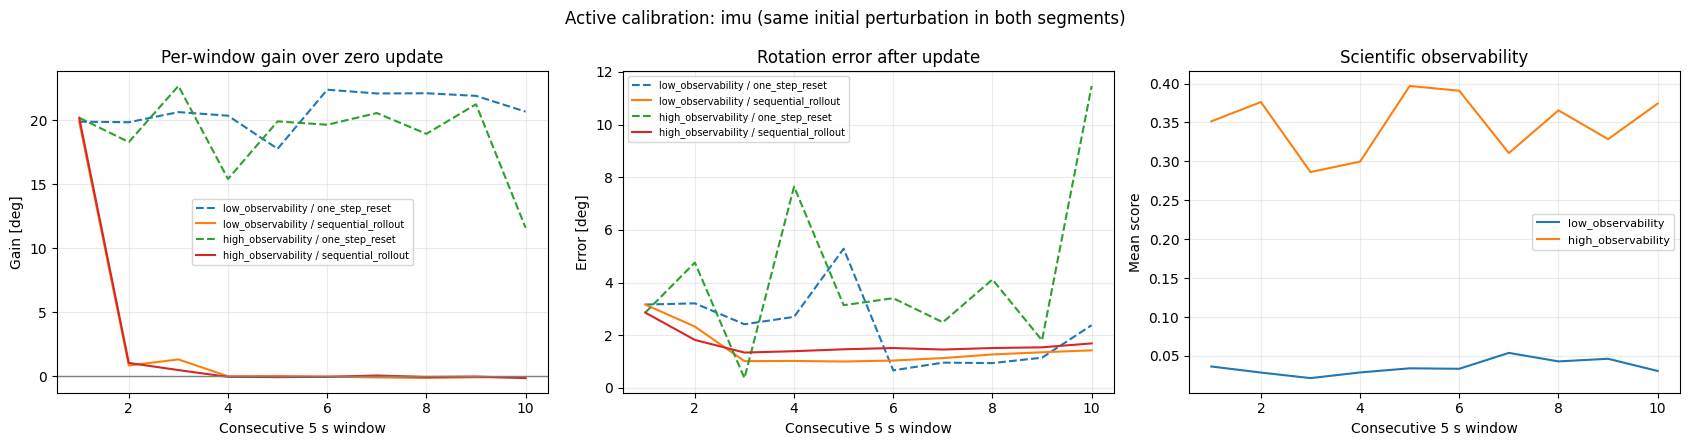

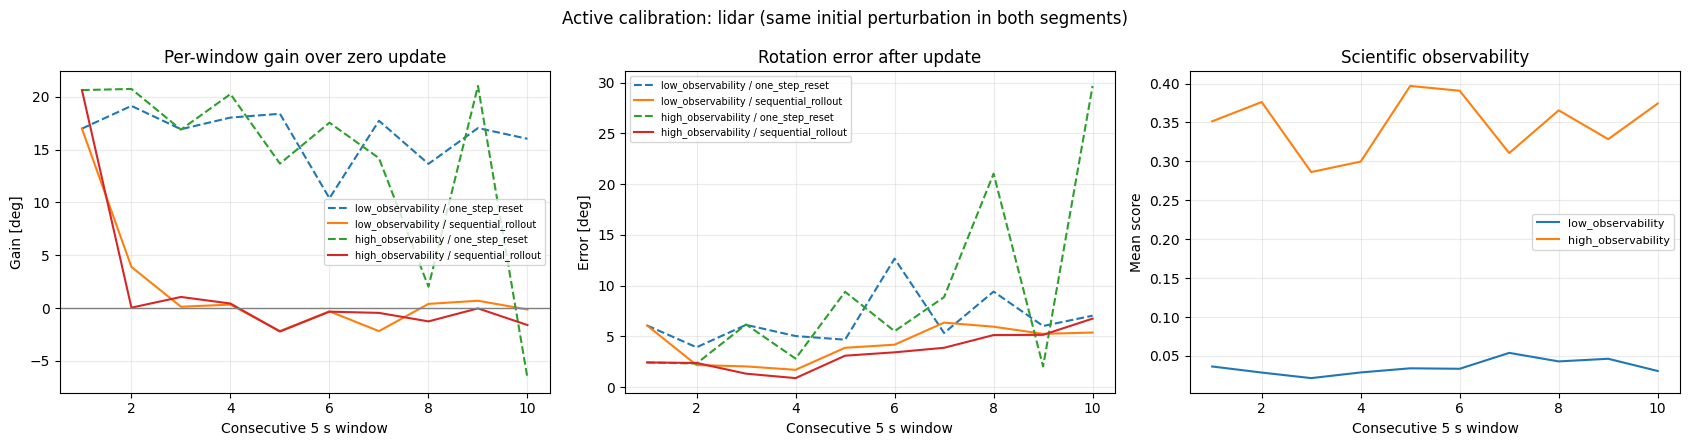

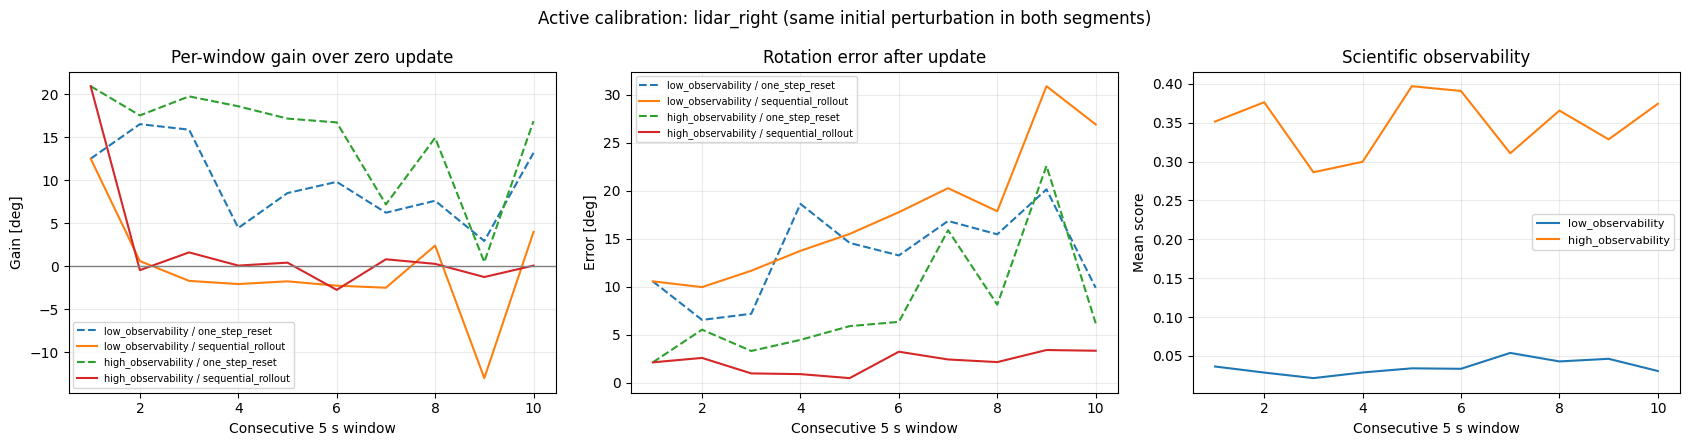

In [29]:
active = results[results.active_sensor].copy()
summary_rows = []
for (scenario, protocol, sensor, segment), group in active.groupby(['scenario', 'protocol', 'sensor', 'segment'], sort=False):
    group = group.sort_values('step')
    summary_rows.append(dict(scenario=scenario, protocol=protocol, sensor=sensor, segment=segment, mean_observability=group.mean_observability.mean(), mean_rotation_observability=group.rotation_observability.mean(), mean_tau_observability=group.tau_observability.mean(), mean_rotation_gain_deg=group.rotation_gain_deg.mean(), fraction_rotation_improving=float((group.rotation_gain_deg > 0).mean()), initial_rotation_error_deg=group.true_rotation_error_before_deg.iloc[0], final_rotation_error_deg=group.true_rotation_error_after_deg.iloc[-1], mean_pred_rotation_deg=float(np.mean(np.linalg.norm(group[[f'pred_phi_{axis}' for axis in 'xyz']].to_numpy(), axis=1))), final_tau_error_before_ms=group.true_tau_error_before_ms.iloc[-1]))
quality_summary = pd.DataFrame(summary_rows)
display(quality_summary.round(3))
quality_summary.to_csv(OUTPUT_DIR / 'calibration_performance_summary.csv', index=False)

for scenario in FAULT_SCENARIOS:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for segment in segments:
        subset = active[(active.scenario == scenario) & (active.segment == segment)]
        for protocol, style in (('one_step_reset', '--'), ('sequential_rollout', '-')):
            g = subset[subset.protocol == protocol].groupby('step', as_index=False).agg(gain=('rotation_gain_deg', 'mean'), error=('true_rotation_error_after_deg', 'mean'), obs=('mean_observability', 'mean'))
            axes[0].plot(g.step, g.gain, linestyle=style, label=f'{segment} / {protocol}')
            axes[1].plot(g.step, g.error, linestyle=style, label=f'{segment} / {protocol}')
        h = subset[subset.protocol == 'one_step_reset']
        axes[2].plot(h.step, h.mean_observability, label=segment)
    for ax, title, ylabel in zip(axes, ('Per-window gain over zero update', 'Rotation error after update', 'Scientific observability'), ('Gain [deg]', 'Error [deg]', 'Mean score')):
        ax.set(title=title, xlabel='Consecutive 5 s window', ylabel=ylabel); ax.grid(alpha=.25)
    axes[0].axhline(0, color='gray', lw=1)
    axes[0].legend(fontsize=7); axes[1].legend(fontsize=7); axes[2].legend(fontsize=8)
    fig.suptitle(f'Active calibration: {scenario} (same initial perturbation in both segments)')
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / f'{scenario}_gain_error_overview.png', dpi=160); plt.show(); plt.close(fig)

## 10 · Seven predicted calibration coordinates over time

Each scenario has **7 rows × 2 columns**: one column for each selected segment; the solid lines are predictions from continuously carried state and the dashed lines are predictions after resetting to the same initial prior. Thin reference lines are the *ideal* updates for the respective priors. This makes it easy to spot small, incorrect, or unobservable corrections. Rotation components in degrees, tangent translations in centimeters, clock offsets in milliseconds.

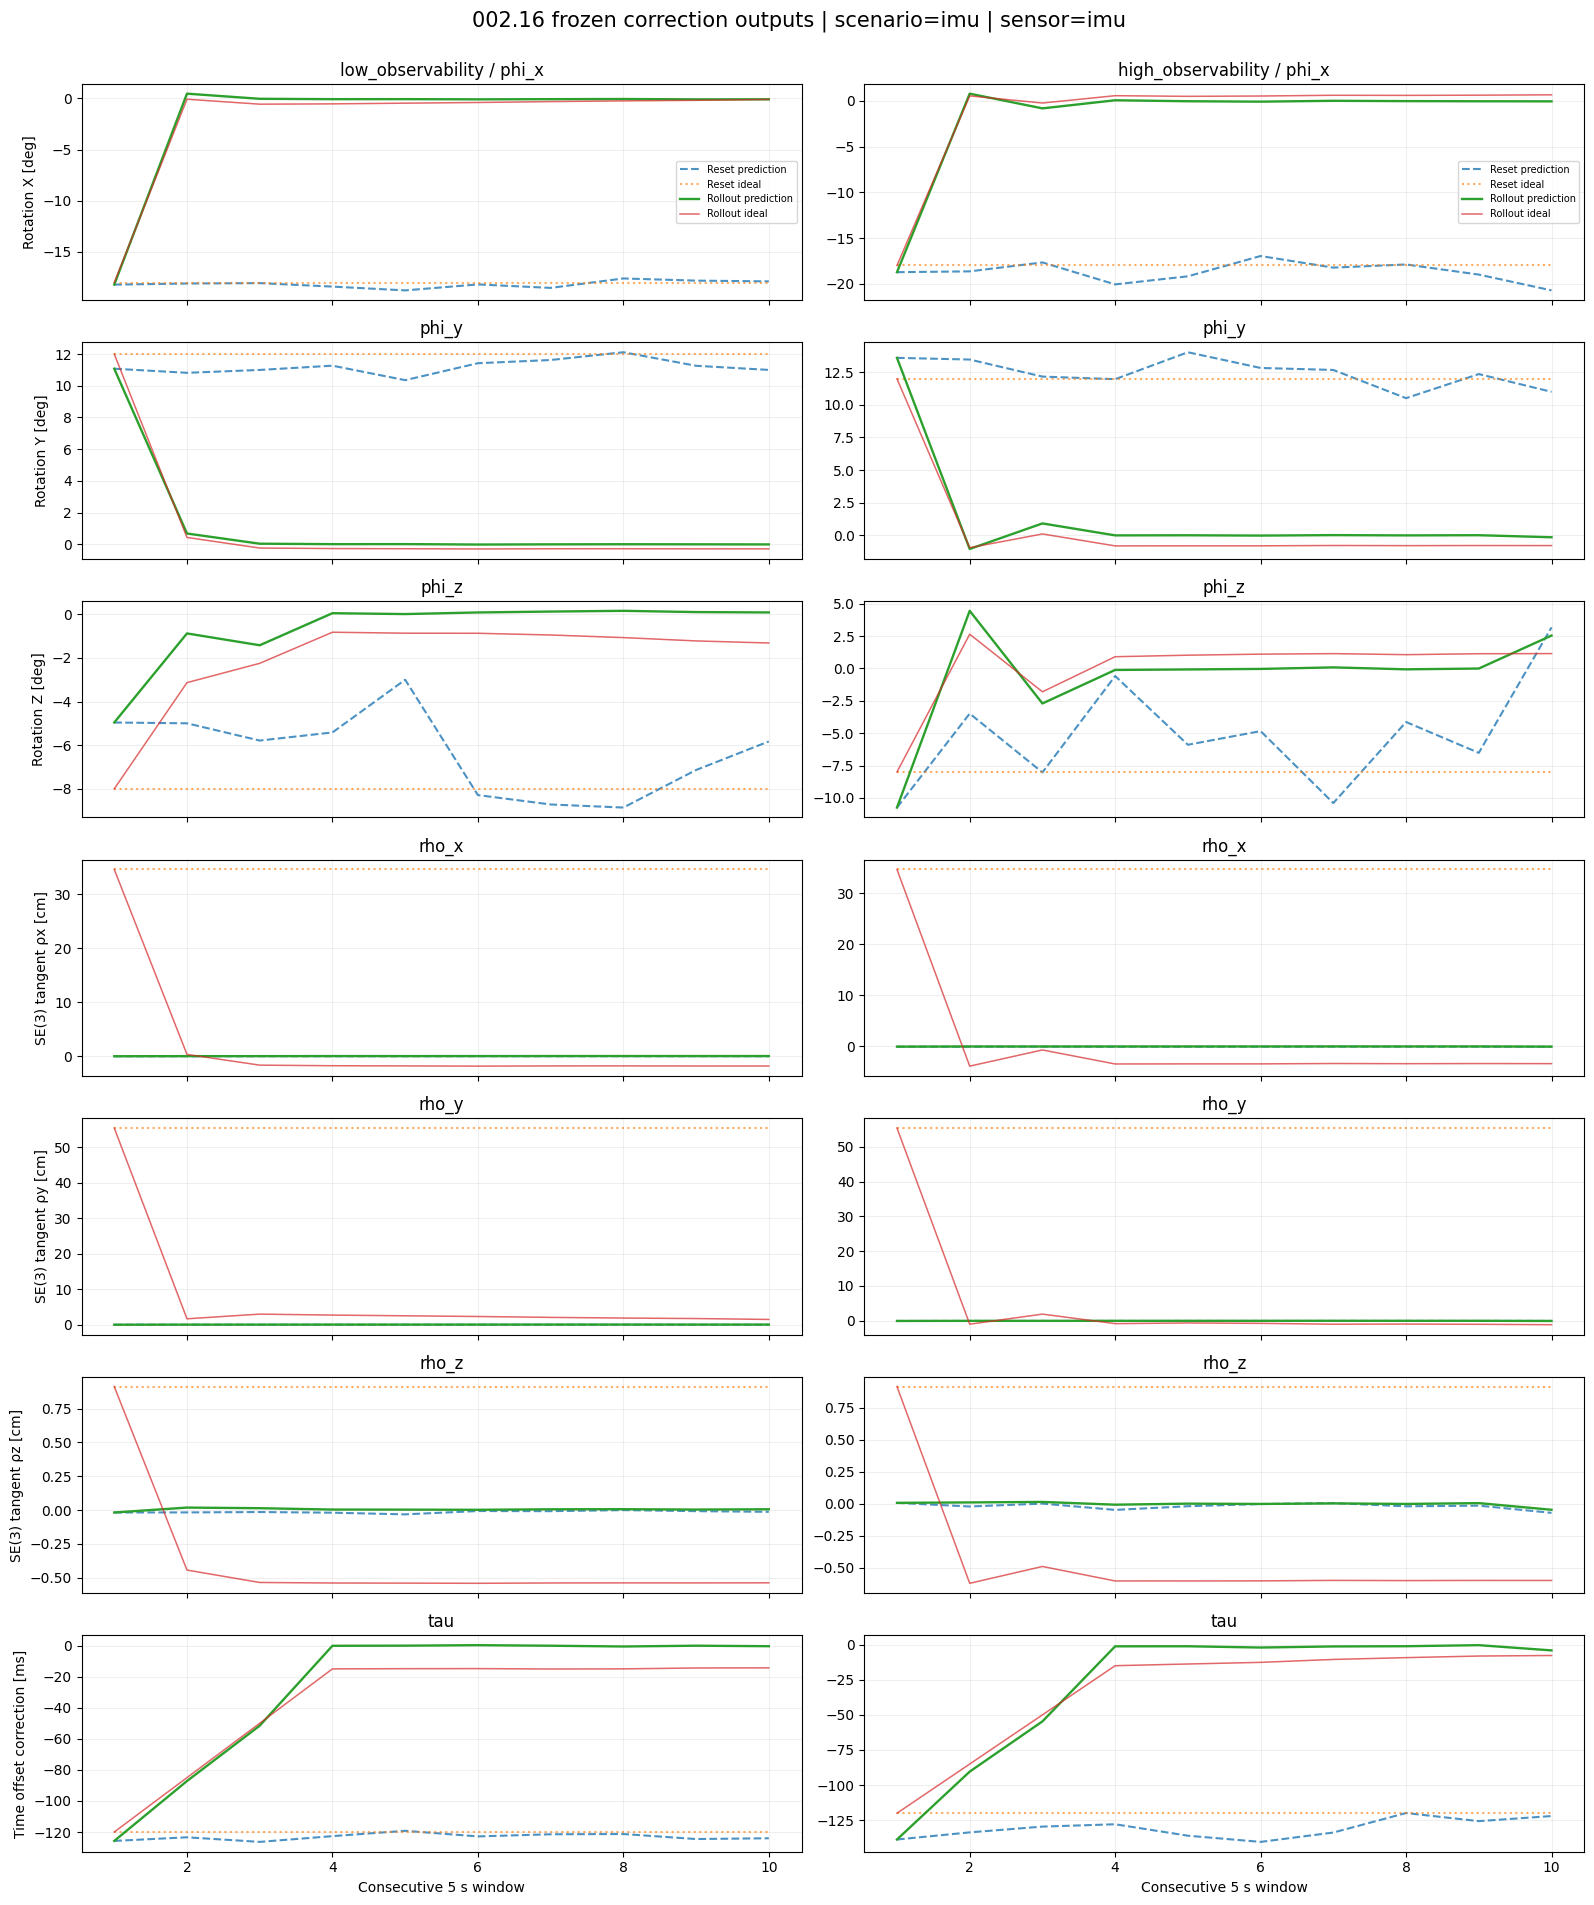

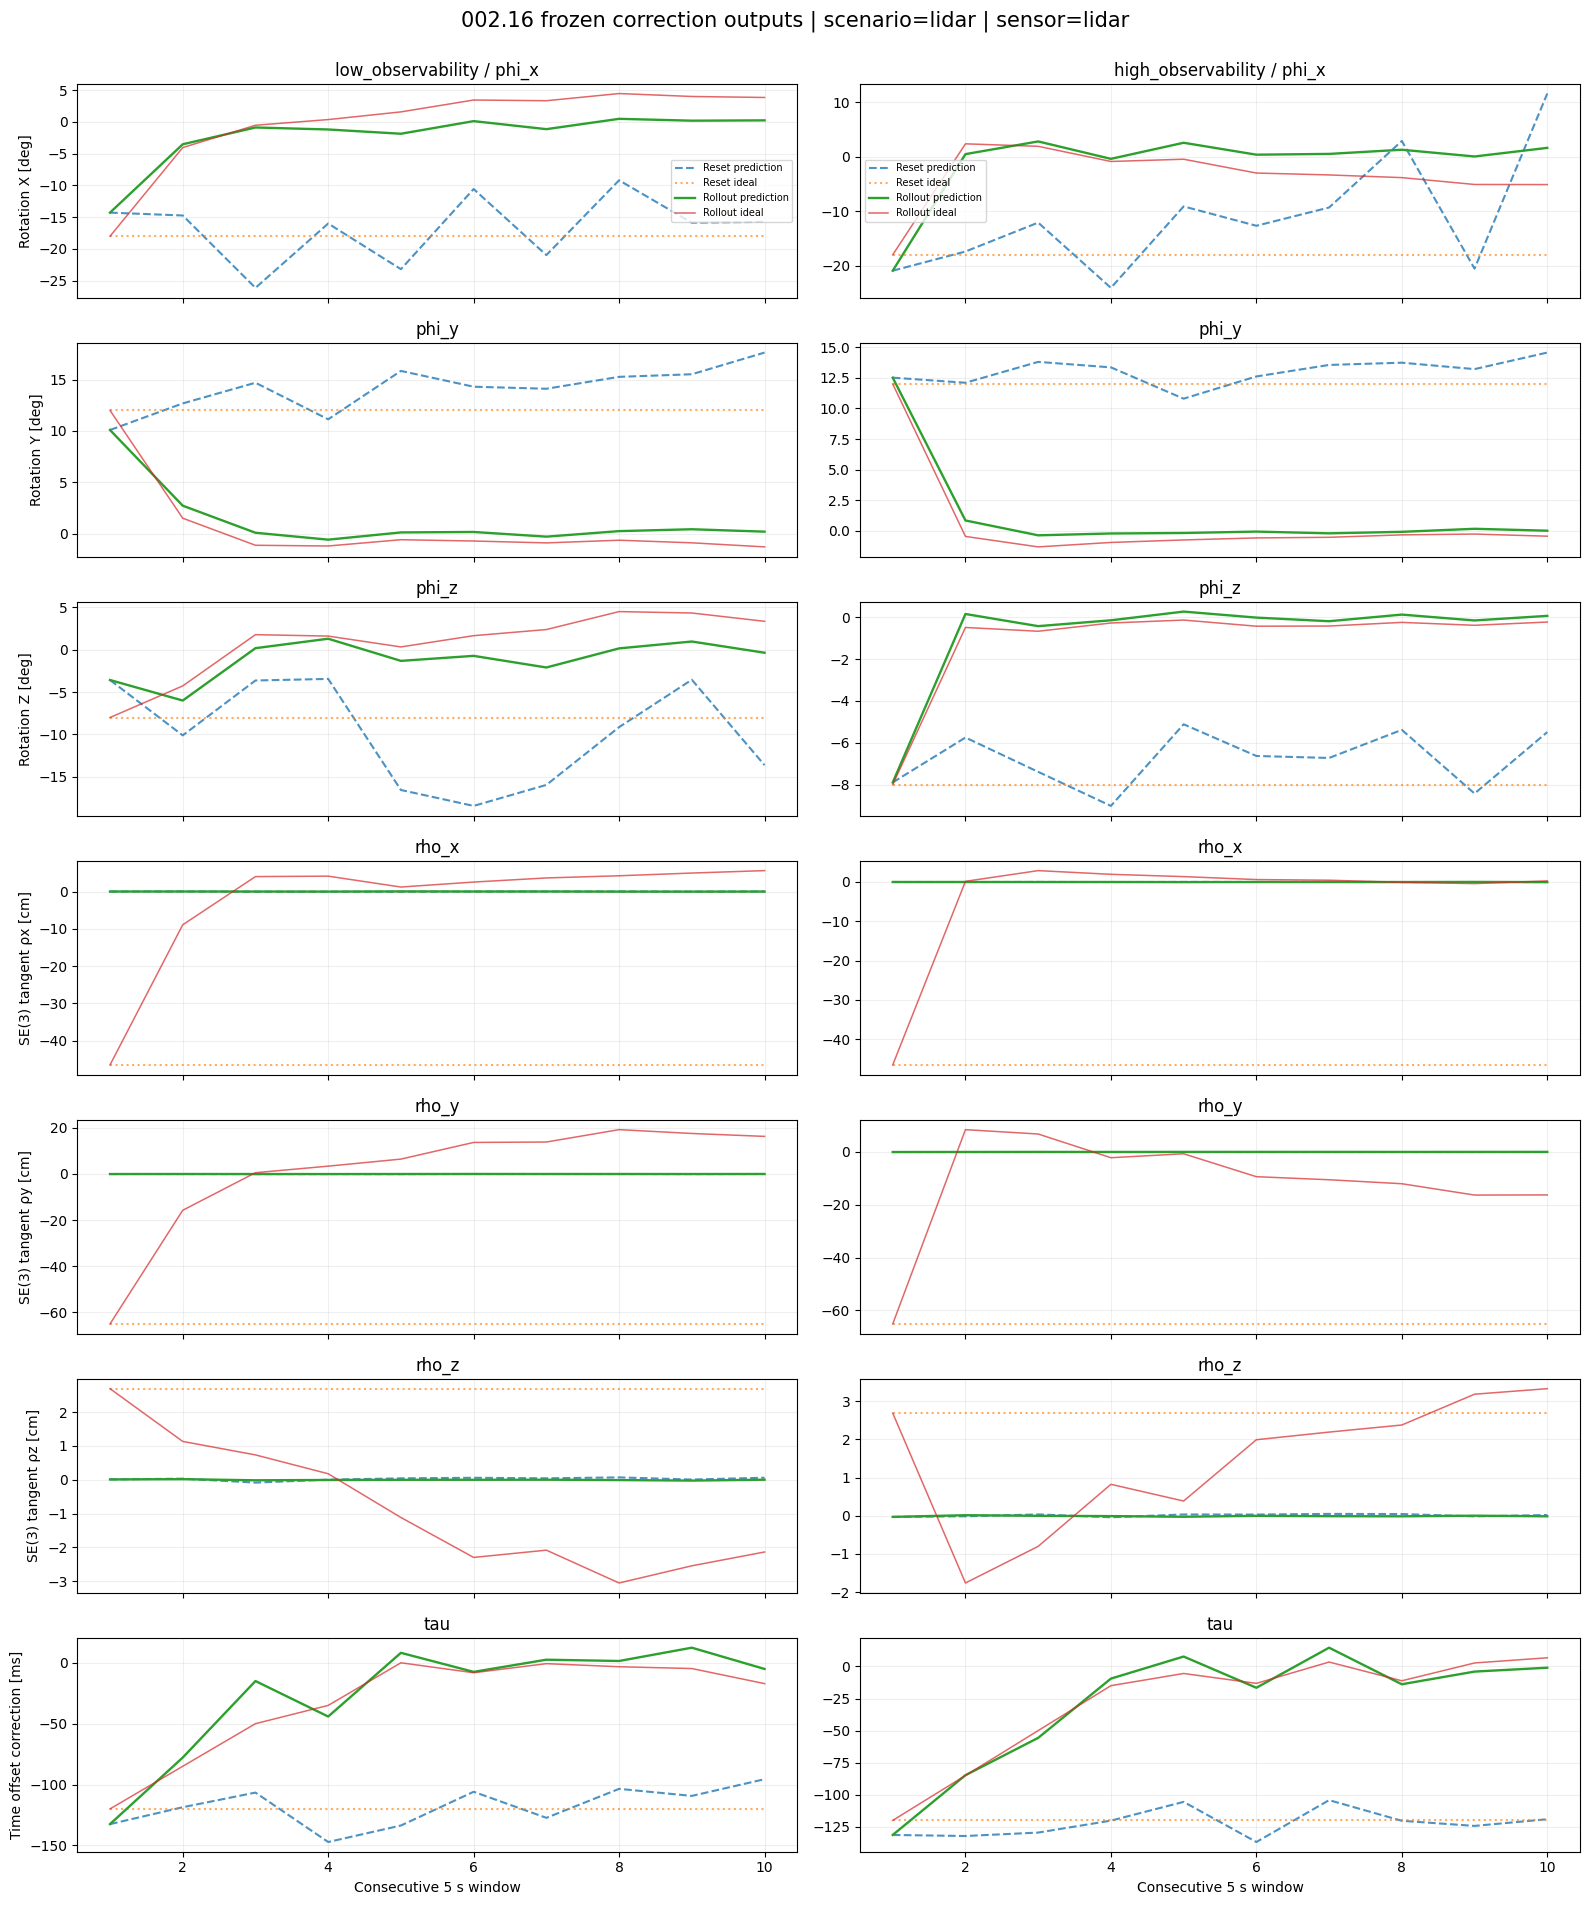

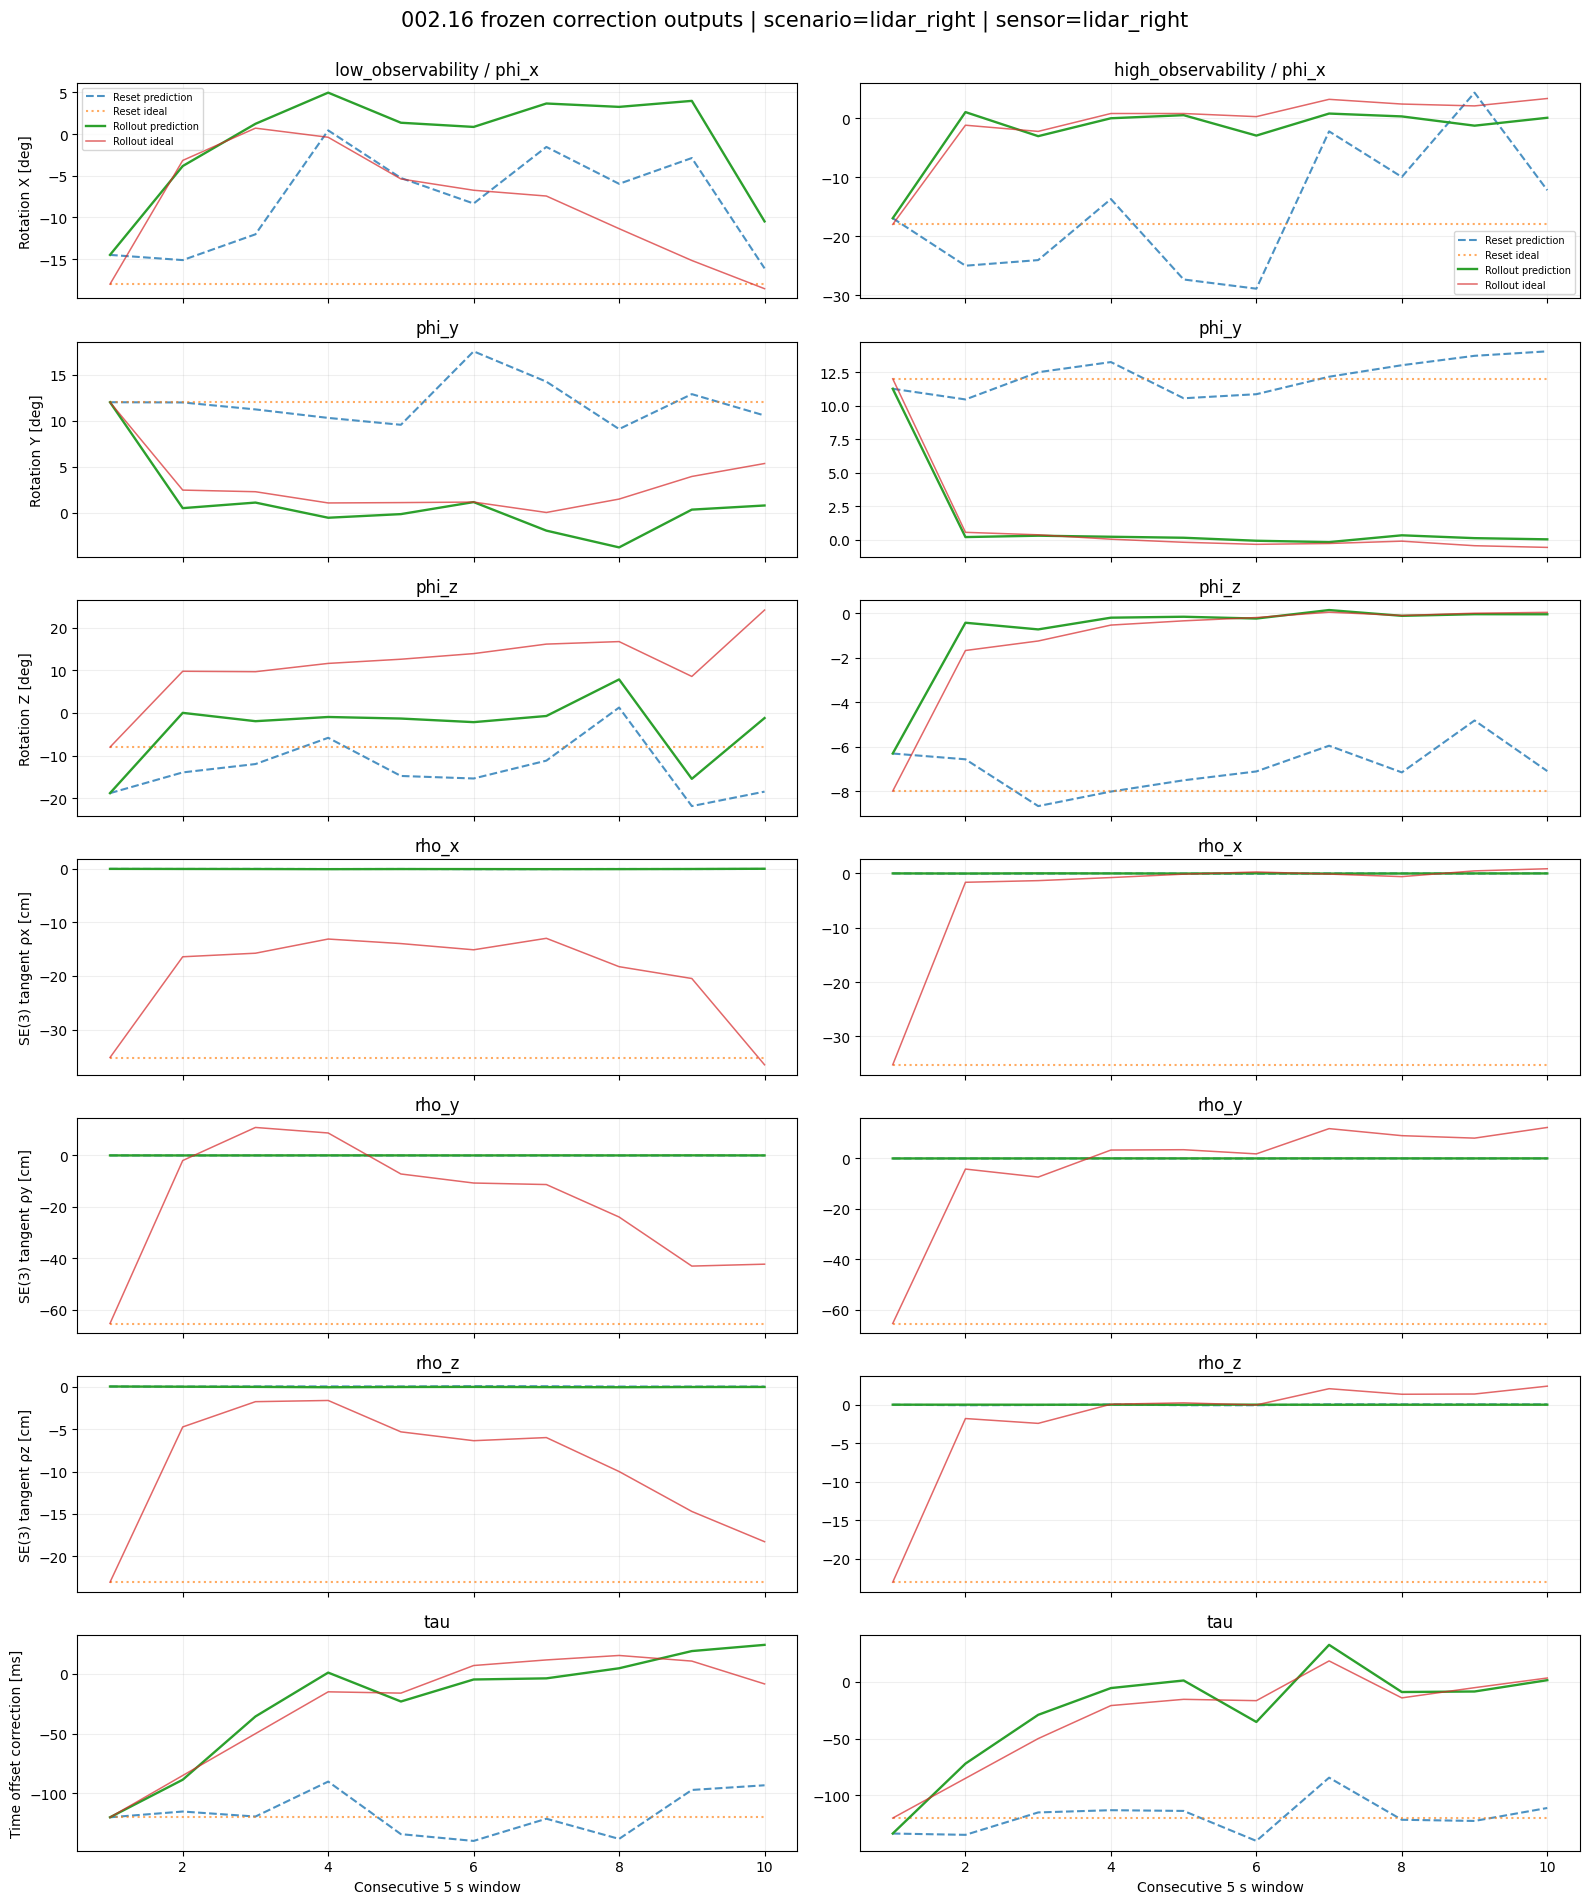

In [30]:
PLOT_COMPONENTS = (("phi_x", 'Rotation X [deg]'), ("phi_y", 'Rotation Y [deg]'), ("phi_z", 'Rotation Z [deg]'), ("rho_x", 'SE(3) tangent ρx [cm]'), ("rho_y", 'SE(3) tangent ρy [cm]'), ("rho_z", 'SE(3) tangent ρz [cm]'), ("tau", 'Time offset correction [ms]'))

for scenario in FAULT_SCENARIOS:
    for key in (CALIBRATION_KEYS if scenario == 'all_sensors' else (scenario,)):
        fig, axes = plt.subplots(7, 2, figsize=(16, 19), sharex='col')
        for column, segment_name in enumerate(segments):
            subset = results[(results.scenario == scenario) & (results.segment == segment_name) & (results.sensor == key)]
            for row, (dof, ylabel) in enumerate(PLOT_COMPONENTS):
                ax = axes[row, column]
                pred_col = 'pred_tau_ms' if dof == 'tau' else f'pred_{dof}'
                ideal_col = 'ideal_tau_ms' if dof == 'tau' else f'ideal_{dof}'
                fixed = subset[subset.protocol == 'one_step_reset'].sort_values('step')
                carried = subset[subset.protocol == 'sequential_rollout'].sort_values('step')
                ax.plot(fixed.step, fixed[pred_col], label='Reset prediction', ls='--', alpha=.8)
                ax.plot(fixed.step, fixed[ideal_col], label='Reset ideal', ls=':', alpha=.65)
                ax.plot(carried.step, carried[pred_col], label='Rollout prediction', lw=1.7)
                ax.plot(carried.step, carried[ideal_col], label='Rollout ideal', lw=1.1, alpha=.7)
                ax.set(ylabel=ylabel if column == 0 else None, title=f'{segment_name} / {dof}' if row == 0 else dof)
                ax.grid(alpha=.2)
                if row == 0: ax.legend(fontsize=7)
        for ax in axes[-1]: ax.set_xlabel('Consecutive 5 s window')
        fig.suptitle(f'002.16 frozen correction outputs | scenario={scenario} | sensor={key}', fontsize=15, y=1.0)
        fig.tight_layout(); fig.savefig(OUTPUT_DIR / f'{scenario}_{key}_seven_dof_predictions.png', dpi=150, bbox_inches='tight'); plt.show(); plt.close(fig)

## 11 · DOF observability versus predicted correction error

A low **mean** could hide high observability for some individual DOFs. The following figure relates each DOF’s scientific nominal score to its one-step prediction error, separately for the two selected segments. A simple correlation is descriptive and does not establish a causal relationship.

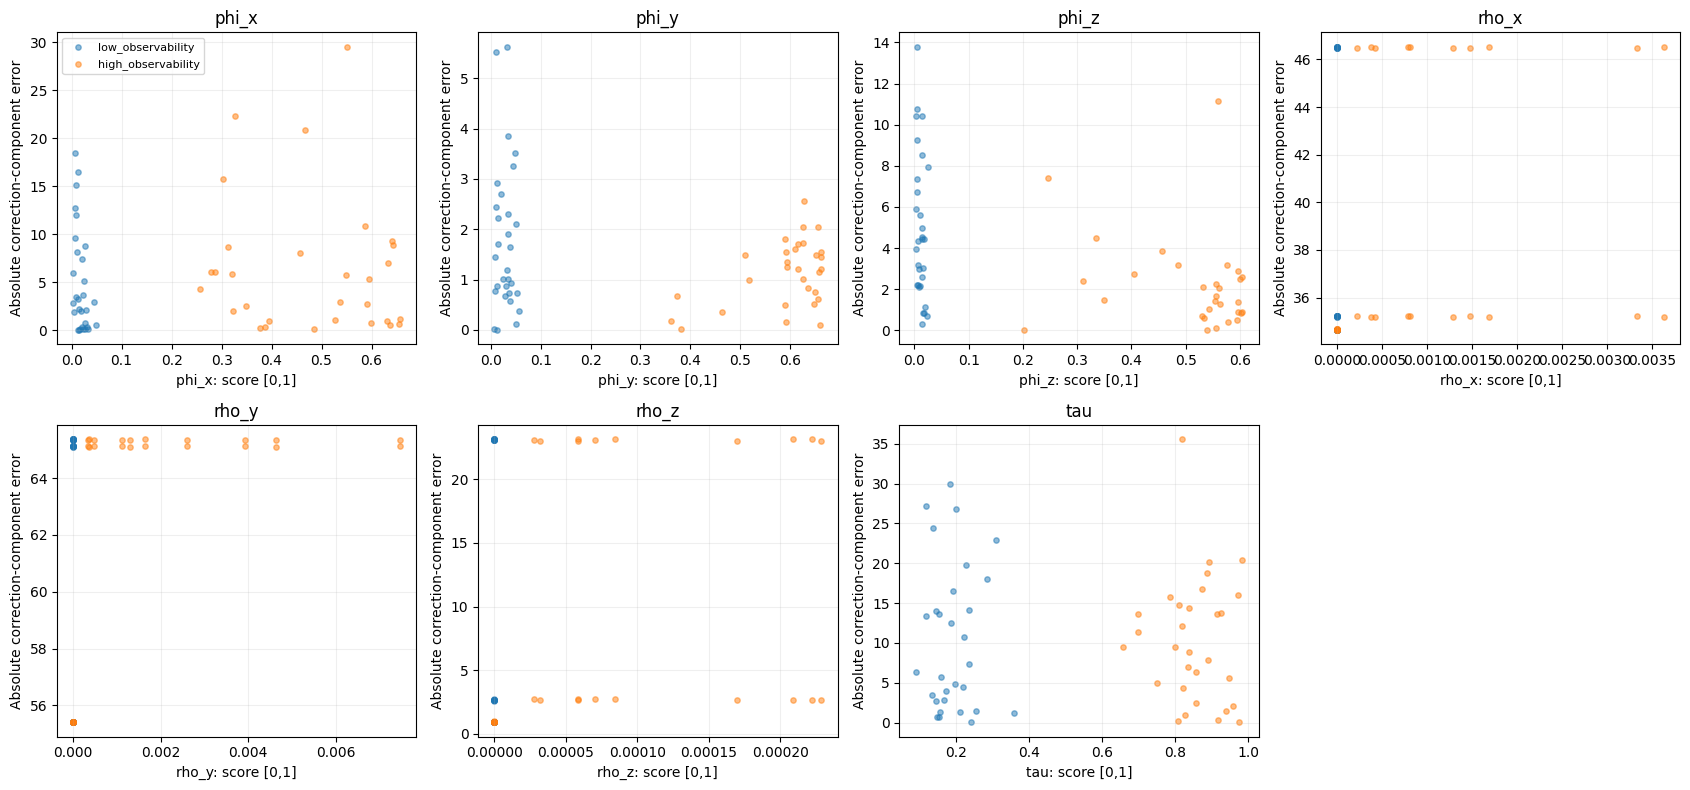

Figures and CSVs saved under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/observability_window_calibration_dynamics
Caution: a low-score 30-window segment need not be straight, and a high-score one need not turn. Interpret the measured yaw plots first.


In [31]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8), squeeze=False)
for ax, (dof, _) in zip(axes.flat, PLOT_COMPONENTS):
    for segment_name, color in (('low_observability', 'tab:blue'), ('high_observability', 'tab:orange')):
        subset = active[(active.protocol == 'one_step_reset') & (active.segment == segment_name)]
        obs_name = f'obs_{dof}'
        predicted_name = 'pred_tau_ms' if dof == 'tau' else f'pred_{dof}'
        true_name = 'ideal_tau_ms' if dof == 'tau' else f'ideal_{dof}'
        ax.scatter(subset[obs_name], np.abs(subset[predicted_name] - subset[true_name]), s=15, alpha=.5, color=color, label=segment_name)
    ax.set(xlabel=f'{dof}: score [0,1]', ylabel='Absolute correction-component error', title=dof); ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis('off')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'per_dof_observability_vs_prediction_error.png', dpi=160); plt.show(); plt.close(fig)

print('Figures and CSVs saved under:', OUTPUT_DIR)
print('Caution: a low-score 30-window segment need not be straight, and a high-score one need not turn. Interpret the measured yaw plots first.')

## 12 · Interpretation guide

- **Low-observability straight-like segment, small predicted updates:** reasonable only if the true fault is not recoverable from that motion. Compare reset predictions with rollout and with the *ideal correction*, not just magnitude.
- **High-observability turn-like segment, better one-step errors:** evidence the frozen network uses motion excitation as expected. Require positive gains on genuinely perturbed DOFs.
- **Scientific scores high but predictions poor:** the Fisher/soft-projector label and learned correction performance are different concepts. Geometry can be locally identifiable yet the frozen model can fail to infer it.
- **Reset correct but rollout drifts:** state feedback/overshooting or biases may dominate; test step gains or acceptance criteria before training new losses.
- **Low/high mean observability without significant yaw contrast:** the cached score extremes did not identify a clean straight-versus-turn physical contrast. Inspect scores by DOF, choose another sequence, or reduce the 30-window length.
- **Translations:** the network emits SE(3) tangent ρ components in every window, but translation updating is disabled by default, so do not interpret the flat physical translation-error curve as evidence of successful learning.

Next experiment: once the two segments are verified physically, compare the frozen 002.16 checkpoint against a yaw-augmented checkpoint using the exact same cached segments and initial perturbations.